## Load modules and libraries

In [1]:
# Load Java/JDK
# Load R/4.3.1

In [ ]:
# Load libraries
import numpy as np
import pandas as pd
import networkx as nx
from dowhy import gcm
from multiprocessing import Pool
import time
import pickle

#from rpy2.robjects import conversion, default_converter, pandas2ri
#from rpy2.robjects.conversion import localconverter
#from rpy2.robjects.packages import importr
#import rpy2.robjects as robjects

import os
import sys
sys.path.insert(1, os.path.join(os.environ['PYTETRAD_HOME'], 'pytetrad'))

#import jpype.imports

#try:
#    jpype.startJVM(classpath=[os.path.join(os.environ['PYTETRAD_HOME'], 'pytetrad', 'resources', 'tetrad-current.jar')])
#except OSError:
#    print("JVM already started")

#from coast.feature_selection import *
#from coast.classify_variable_relationships import *
#from coast.causal_graph_gcastle import *
from coast.causal_model import *
from coast.distribution_change_new import *
from coast.optimization import *
from coast.optimization_parallelization import *
from coast.pathway_analysis import *
from coast.utils import *

import matplotlib.pyplot as plt
import dowhy.utils.plotting as dowhy_plot

import warnings
warnings.filterwarnings("ignore")

## Data Preprocessing

### Load data

In [2]:
with open("../../uhlerlab-actlearn/data/data+.pkl", 'rb') as f:
	data_dict = pickle.load(f)
with open("../../uhlerlab-actlearn/data/gene_dict.pkl", 'rb') as f:
	gene_dict = pickle.load(f)

In [ ]:
data = data_dict['ctrl'][3].T  #cells X genes
data_new = np.load('../../uhlerlab-actlearn/data/samples+/pure_CTSD.npy')
#data_new = np.load('../../uhlerlab-actlearn/data/samples+/pure_TGFB1.npy')
#data_new = np.load('../../uhlerlab-actlearn/data/samples+/pure_B2M.npy')
print(data.shape)
print(data_new.shape)

(5039, 36)
(170, 36)


In [ ]:
# Define source state data and target state data
source_data = pd.DataFrame(data, columns=list(gene_dict.keys()))
target_data = pd.DataFrame(data_new, columns=list(gene_dict.keys()))

# In this example, we skipped the feature selection step and used the source_data and target_data defined above for downstream analyses

## Causal discovery and modeling

### Causal discovery

In [5]:
with open("../../uhlerlab-actlearn/data/estimated_dag.pkl", 'rb') as f:
	causal_graph = pickle.load(f)

print("# of edges:", len([e for e in causal_graph.edges]))
print("# of nodes:", len([node for node in causal_graph.nodes]))

# of edges: 144
# of nodes: 36


### Causal modeling

In [6]:
# Define a model (SCM) based on the causal graph
causal_model = gcm.StructuralCausalModel(causal_graph)
# Assign causal mechanisms to each node (automatically)
# gcm.auto.assign_causal_mechanisms(causal_model, data)
custom_mechanisms(causal_graph, causal_model)
# Fit the model to the data
gcm.fit(causal_model, source_data)

Fitting causal mechanism of node TGFB1: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 36/36 [00:00<00:00, 144.75it/s]


## Optimization

In [7]:
# Initialization
causal_object = CausalClass(data_old=source_data, data_new=target_data, causal_graph=causal_graph, causal_model=causal_model)
causal_object.get_total_changes()
causal_object.fit_old_model_on_new_data()

Total changes: 10.432196052810813


Fitting causal mechanism of node TGFB1: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 36/36 [00:00<00:00, 198.52it/s]


### Root cause analysis

In [8]:
mechanism_changes = causal_object.check_mechanism_changes()
with open('mechanism_changes.pkl', 'wb') as file:
    pickle.dump(mechanism_changes, file)

[Parallel(n_jobs=16)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  36 out of  36 | elapsed:    6.2s finished


Fitting for B2M
Fitting for CCR10
Fitting for CD58
Fitting for CD59
Fitting for CDH19
Fitting for CDK4
Fitting for CDK6
Fitting for CTSA
Fitting for CTSB
Fitting for CXCR4
Fitting for DNMT1
Fitting for EIF3K
Fitting for FOS
Fitting for HLA-A
Fitting for HLA-B
Fitting for HLA-C
Fitting for HLA-E
Fitting for IFNGR1
Fitting for IFNGR2
Fitting for IRF3
Fitting for LAMP2
Fitting for MYC
Fitting for NGFR
Fitting for NPC1
Fitting for NPC2
Fitting for RB1
Fitting for SAT1
Fitting for SEC11C
Fitting for SERPINE2
Fitting for SMAD4
Fitting for SOX4
Fitting for SP100
Fitting for STAT1
Fitting for STAT3
Fitting for TGFB1


Estimating mechanism change anomaly scores: 100%|██████████████████████████████████████████████████████████████████████████████████████████| 36/36 [00:00<00:00, 3437.64it/s]


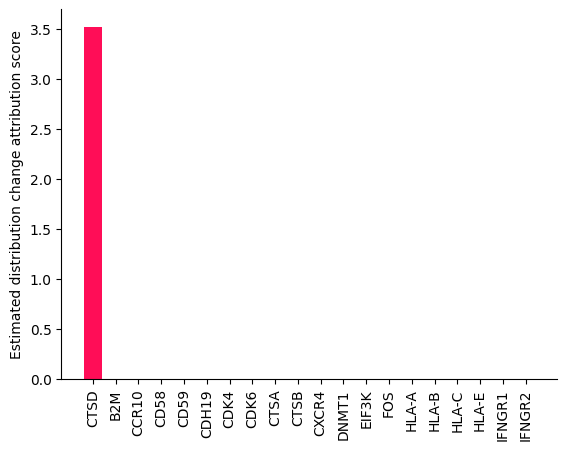

In [9]:
### Approach 1 (modified from dowhy, very quick)
attrib_scores_est = estimate_distribution_change_scores_optimized(causal_model, source_data, target_data, mechanism_changed_for_node=mechanism_changes, difference_estimation_func=lambda x, y: np.mean(y) - np.mean(x))
attrib_scores_est = sort_nodes(attrib_scores_est)
attrib_scores_est = {k: abs(v) for k, v in attrib_scores_est.items()}
attrib_scores_est_for_plot = dict(list(attrib_scores_est.items())[:20])
dowhy_plot.bar_plot(attrib_scores_est_for_plot, ylabel='Estimated distribution change attribution score')#, display_plot=False)
#plt.tight_layout()
#plt.savefig('{}/attrib_scores_est.png'.format(savedir))
#plt.close()
with open('attrib_scores_est.pkl', 'wb') as file:
    pickle.dump(attrib_scores_est, file)

# of DE variables: 2
Variable is: EIF3K
Variable is: CTSD


[Parallel(n_jobs=16)]: Using backend LokyBackend with 16 concurrent workers.
Evaluating set functions...: 100%|██████████| 238/238 [00:05<00:00, 46.77it/s]
[Parallel(n_jobs=16)]: Done   2 out of   2 | elapsed:    7.8s finished


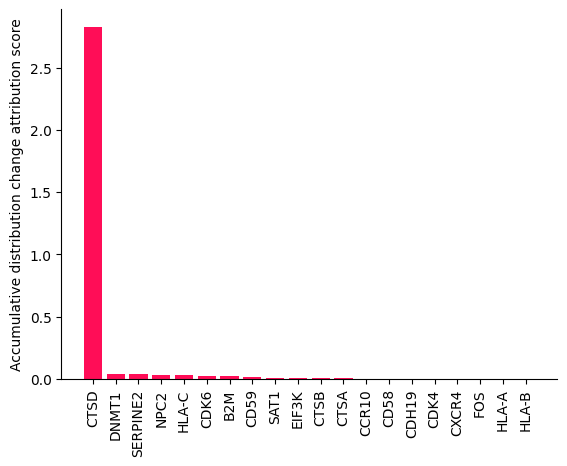

In [10]:
### Approach 2 (accumulative attribution scores):
attrib_scores = get_attribution_scores_parallel_standalone(causal_object, de_cols=None, test='parametric', alpha=0.05)
attrib_scores_for_plot = dict(list(attrib_scores.items())[:20])
dowhy_plot.bar_plot(attrib_scores_for_plot, ylabel='Accumulative distribution change attribution score')#, display_plot=False)
#plt.tight_layout()
#plt.savefig('{}/attrib_scores.png'.format(savedir))
#plt.close()
with open('attrib_scores.pkl', 'wb') as file:
    pickle.dump(attrib_scores, file)

In [11]:
# Get candidate nodes
top_nodes, normalized_attributions = causal_object.adaptive_selection(attrib_scores, delta=0.01)
print(f'Adaptive selection of top nodes completed, {len(top_nodes)} nodes were selected')

Adaptive selection of top nodes completed, 5 nodes were selected


### Optimize by regularization approach

In [15]:
solutions_reg = get_perturbation_targets_by_reg_parallel_standalone(causal_object, top_nodes=top_nodes, attrib_scores=attrib_scores, 
                                                                    minval=-5000, maxval=5000, maxiter=10000, 
                                                                    minimize_target_state_change=False, gamma=1e-2)
solutions_reg.to_csv('solutions_reg.csv', index=False)
solutions_reg_processed = causal_object.process_results_by_reg(solutions_reg, thres_val=1e-1)
solutions_reg_processed.to_csv('solutions_reg_processed.csv', index=False)

Using 16 workers for parallel regularization optimization
Optimizing over 5 nodes: ['CTSD', 'DNMT1', 'SERPINE2', 'NPC2', 'HLA-C']
Computed weights (sum=1.0000)
Computing lambda range with 20 points...
Lambda range: [1764.6601, 1.7647]
Evaluating 20 lambda values...


[Parallel(n_jobs=16)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  10 out of  20 | elapsed:   52.9s remaining:   52.9s
[Parallel(n_jobs=16)]: Done  20 out of  20 | elapsed:  1.2min finished


Successfully optimized 20/20 lambda values


Text(0.5, 0, 'Regularization Parameter Value')

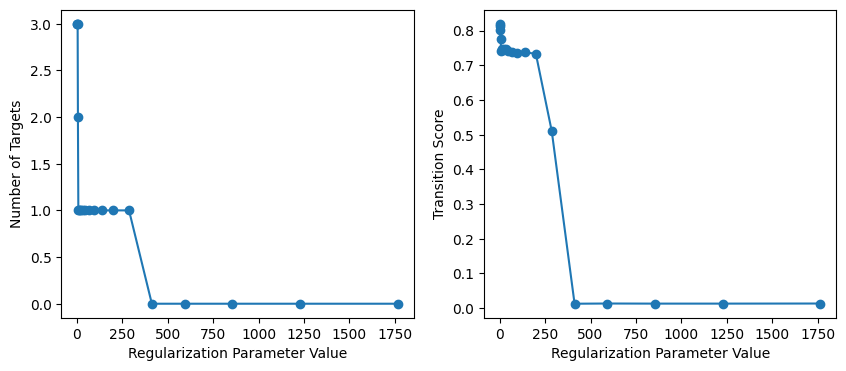

In [16]:
plot_df = solutions_reg_processed.sort_values(by='Lambda')
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].plot(plot_df['Lambda'], plot_df['# of intervention targets'], marker='o')
axs[0].set_ylabel('Number of Targets')
axs[0].set_xlabel('Regularization Parameter Value')
axs[1].plot(plot_df['Lambda'], plot_df['TransProp'], marker='o')
axs[1].set_ylabel('Transition Score')
axs[1].set_xlabel('Regularization Parameter Value')
#plt.savefig(f'{savedir}/reg_top_{len(top_nodes)}_nodes.png')
#plt.close()